# Etapa II · Fase 2 · Bloque C-1: comparación de clasificadores

**Pregunta del bloque:** con el mismo texto y la misma representación, ¿cuál de los tres clasificadores funciona mejor?

| | |
|---|---|
| **X (entrada)** | `title + ". " + abstract`, normalizado |
| **y (objetivo)** | `primary_category` ∈ {cs.CL, cs.CV, cs.IR, cs.LG} |
| **Tarea** | Clasificación multiclase, una etiqueta por documento |
| **Factor que cambia** | El clasificador: MultinomialNB, LogisticRegression, SVC lineal |
| **Fijo** | Normalización N2, TF-IDF, unigramas `(1,1)`, sin SVD |

Código: `src/etapa2/classify.py`. También se puede correr desde la terminal con `python -m src.etapa2.classify C-1`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.etapa2 import config
from src.etapa2.classify import build_pipeline, run_block_c1, summary, cv_table, confusion_table
from src.etapa2.labels import load_labeled
from src.etapa2.normalization import load_variants
from src.etapa2.tracking import load_experiments

pd.set_option("display.max_colwidth", 80)
df = load_labeled()
print(df["split"].value_counts().to_dict())

{'train': 350, 'test': 75, 'dev': 75}


## 1. Justificación de cada parámetro

### Lo que queda fijo en C-1

| Parámetro | Valor | Por qué |
|---|---|---|
| Normalización | **N2** | Es la normalización de la Etapa I y la que deja el vocabulario más compacto (6 689 términos en train). Sirve de punto de partida; el bloque C-2 compara N0, N1 y N2. |
| Representación | **TF-IDF** | Baja el peso de palabras que aparecen en casi todos los abstracts (*model*, *method*, *propose*) y sube el de las que distinguen un área (*retrieval*, *image*, *translation*). Es la opción estándar para texto; C-3 la compara con binaria y frecuencia. |
| n-gramas | **(1,1)** | Es lo más simple y deja una línea base limpia. C-4 prueba bigramas y trigramas. |
| SVD | **No** | MultinomialNB no admite los valores negativos que produce SVD. Para comparar los tres en igualdad, C-1 va sin SVD; C-5 lo prueba con LR y SVC. |
| `lowercase=False` y tokenizador por espacios | — | El texto ya viene normalizado. Si el vectorizador volviera a pasar a minúsculas y a quitar puntuación, N0 quedaría igual que N1 y el bloque C-2 no mediría nada. |

### Lo que se busca con validación cruzada

| Parámetro | Valores | Por qué |
|---|---|---|
| `min_df` (vectorizador) | {1, 2} | Con 1 se conservan todas las palabras. Con 2 se eliminan las que salen en un solo documento (nombres propios, siglas raras, erratas), que no ayudan a generalizar. Más abajo se ve que son casi la mitad del vocabulario. |
| `alpha` (NB) | {0.1, 0.5, 1.0} | Suavizado de Laplace: evita probabilidad 0 para palabras que no aparecieron en una clase. 1.0 es el valor por defecto; valores menores confían más en los conteos observados, lo que suele ayudar con vocabularios grandes y dispersos. |
| `C` (LR y SVC) | {0.1, 1, 10} | Inverso de la regularización. Hay ~6 700 rasgos y solo 350 documentos, así que el modelo puede memorizar train fácilmente; C pequeño lo frena. Escala logarítmica porque el efecto de C es multiplicativo. |

### Configuración fija de cada modelo

| Modelo | Configuración | Por qué |
|---|---|---|
| MultinomialNB | por defecto | Modela conteos de palabras por clase. Es la línea base clásica para texto: rápido y sin hiperparámetros delicados. Acepta TF-IDF porque solo necesita valores no negativos. |
| LogisticRegression | `max_iter=2000` | Con el valor por defecto (100), `lbfgs` puede no converger con miles de rasgos y avisa con `ConvergenceWarning`. Regularización L2 por defecto y salida multinomial para las 4 clases. |
| SVC | `kernel="linear"` | El texto en TF-IDF tiene miles de dimensiones y casi siempre es separable con un hiperplano. Un kernel RBF agregaría `gamma` y rara vez mejora en texto disperso. |
| Todos | `random_state=0` | Reproducibilidad. |

### Cómo se busca y cómo se mide

| Parámetro | Valor | Por qué |
|---|---|---|
| Búsqueda | `GridSearchCV` **solo sobre train** | Dev y test no participan en el ajuste: no hay fuga. |
| Validación cruzada | `StratifiedKFold(5, shuffle=True, random_state=0)` | 5 particiones de ~70 documentos (~17 por clase). Estratificar mantiene las 4 clases balanceadas en cada partición; 10 particiones dejarían muy pocos documentos por clase. |
| Métrica | `f1_macro` | Promedia el F1 de las 4 clases por igual: un modelo que falla en una clase queda penalizado aunque su accuracy sea buena. Es la métrica de selección del proyecto. |
| Evaluación | dev (75 docs) | Compara pipelines ya ajustados. Test no se toca hasta la Fase 3. |

### Evidencia para `min_df`: palabras que aparecen en un solo documento de train

In [2]:
variants = load_variants().set_index("document_id")
train_ids = df.loc[df["split"] == "train", "document_id"]
doc_freq = pd.Series([t for d in variants.loc[train_ids, "text_n2"] for t in set(d.split())]).value_counts()
hapax = (doc_freq == 1).sum()
print(f"Vocabulario N2 en train: {len(doc_freq)} términos")
print(f"Aparecen en un solo documento: {hapax} ({hapax / len(doc_freq):.0%})")
print("Ejemplos:", ", ".join(doc_freq[doc_freq == 1].sample(12, random_state=0).index))

Vocabulario N2 en train: 6689 términos
Aparecen en un solo documento: 3656 (55%)
Ejemplos: rsoc, composed, https://github.com/reml-ai/visionq, possibly, disproportionately, wixqa, budgeted, renormalized, donor, hmm, 0.813, anatomy


### El pipeline
Cada experimento entrena esta cadena completa. `NormalizedText` recibe el `document_id` y devuelve el texto N2 de la caché.

In [3]:
build_pipeline("LogisticRegression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('norm', ...), ('vec', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variant,'N2'
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",False
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function whi...x7f8e2c9c4b40>
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",None
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


## 2. Ejecución del bloque C-1
Cada modelo prueba sus combinaciones de hiperparámetros × 5 particiones. El mejor se reentrena en todo train y se evalúa en dev.

In [4]:
results = run_block_c1(df)
res = summary(results)
res.round(4)

,model,normalization,representation,ngram_range,svd_components,best_params,cv_macro_f1,cv_std,dev_accuracy,dev_macro_f1,n_features,fit_seconds
experiment_id,,,,,,,,,,,,
C01,MultinomialNB,N2,tfidf,"(1, 1)",None,alpha=0.5; min_df=2,0.7594,0.0213,0.7600,0.7607,3033,4.8810
C02,LogisticRegression,N2,tfidf,"(1, 1)",None,C=1; min_df=1,0.7675,0.0219,0.8000,0.7993,6689,1.5884
C03,SVC,N2,tfidf,"(1, 1)",None,C=1; min_df=1,0.7478,0.0334,0.7467,0.7481,6689,1.3313


**Cómo leer la tabla**
- `cv_macro_f1` ± `cv_std`: F1 macro promedio en las 5 particiones de train. Es la estimación más estable.
- `dev_macro_f1`: F1 macro en dev. Con 75 documentos, **un documento vale ~1.3 puntos**, así que diferencias de 1-2 puntos no son concluyentes.
- `n_features`: tamaño del vocabulario tras `min_df`.

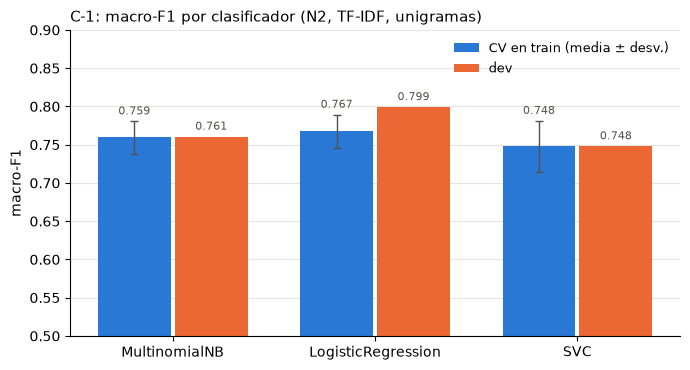

In [5]:
COLORS = {"cv": "#2a78d6", "dev": "#eb6834"}
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(res))
w = 0.36
b1 = ax.bar(x - w/2 - 0.01, res["cv_macro_f1"], w, yerr=res["cv_std"], color=COLORS["cv"],
            label="CV en train (media ± desv.)", error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
b2 = ax.bar(x + w/2 + 0.01, res["dev_macro_f1"], w, color=COLORS["dev"], label="dev")
ax.bar_label(b1, fmt="%.3f", padding=3, fontsize=8, color="#52514e")
ax.bar_label(b2, fmt="%.3f", padding=3, fontsize=8, color="#52514e")
ax.set_xticks(x, res["model"])
ax.set_ylabel("macro-F1")
ax.set_ylim(0.5, 0.9)
ax.set_title("C-1: macro-F1 por clasificador (N2, TF-IDF, unigramas)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "C-1_macro_f1.png", dpi=150)
plt.show()

## 3. Hiperparámetros: cómo le fue a cada combinación en la CV

In [6]:
for r in results:
    print(f"\n{r['experiment_id']} · {r['model']}  →  elegido: {r['best_params']}")
    display(cv_table(r).round(4))


C01 · MultinomialNB  →  elegido: alpha=0.5; min_df=2


,alpha,min_df,cv_macro_f1,cv_std
0,0.5,2,0.7594,0.0213
1,0.1,2,0.7513,0.0402
2,1.0,2,0.7496,0.0231
3,0.1,1,0.7313,0.0286
4,1.0,1,0.7141,0.0231
5,0.5,1,0.7071,0.0237



C02 · LogisticRegression  →  elegido: C=1; min_df=1


,C,min_df,cv_macro_f1,cv_std
0,1.0,1,0.7675,0.0219
1,1.0,2,0.7602,0.0161
2,0.1,2,0.7574,0.0178
3,0.1,1,0.7535,0.0184
4,10.0,1,0.7451,0.0228
5,10.0,2,0.7449,0.0230



C03 · SVC  →  elegido: C=1; min_df=1


,C,min_df,cv_macro_f1,cv_std
0,1.0,1,0.7478,0.0334
1,1.0,2,0.7378,0.0259
2,10.0,1,0.7296,0.0290
3,10.0,2,0.7109,0.0374
4,0.1,2,0.2136,0.2317
5,0.1,1,0.2084,0.2215


**Lectura de la búsqueda**
- **NB:** `min_df=2` gana con cualquier `alpha` (+2 a 4 puntos). Quitar las palabras de un solo documento le ayuda porque NB las cuenta como evidencia aunque sean ruido. `alpha=0.5` queda en medio del rango, así que el rango probado es adecuado.
- **LR:** `C=1` es el mejor y las diferencias son pequeñas (0.745-0.768). Es poco sensible a `min_df`, porque la regularización ya le resta peso a las palabras raras.
- **SVC:** con `C=0.1` **colapsa** (F1 ≈ 0.21): la regularización es tan fuerte que el modelo predice casi todo como una sola clase. Los vectores TF-IDF tienen norma 1 y las márgenes quedan muy pequeñas, así que SVC necesita `C ≥ 1`. Es una razón para conservar 1 y 10 en la rejilla.
- En los tres el valor elegido queda **en medio** del rango, no en un extremo: no hace falta ampliar la rejilla.

## 4. Reporte por clase en dev

In [7]:
for r in results:
    print(f"=== {r['experiment_id']} · {r['model']} ===")
    print(r["report"])

=== C01 · MultinomialNB ===
              precision    recall  f1-score   support

       cs.CL      0.722     0.684     0.703        19
       cs.CV      0.929     0.684     0.788        19
       cs.IR      0.762     0.889     0.821        18
       cs.LG      0.682     0.789     0.732        19

    accuracy                          0.760        75
   macro avg      0.774     0.762     0.761        75
weighted avg      0.774     0.760     0.760        75

=== C02 · LogisticRegression ===
              precision    recall  f1-score   support

       cs.CL      0.722     0.684     0.703        19
       cs.CV      0.882     0.789     0.833        19
       cs.IR      0.810     0.944     0.872        18
       cs.LG      0.789     0.789     0.789        19

    accuracy                          0.800        75
   macro avg      0.801     0.802     0.799        75
weighted avg      0.801     0.800     0.798        75

=== C03 · SVC ===
              precision    recall  f1-score   suppo

## 5. Matrices de confusión en dev
Filas = clase real, columnas = clase predicha. La diagonal son aciertos.

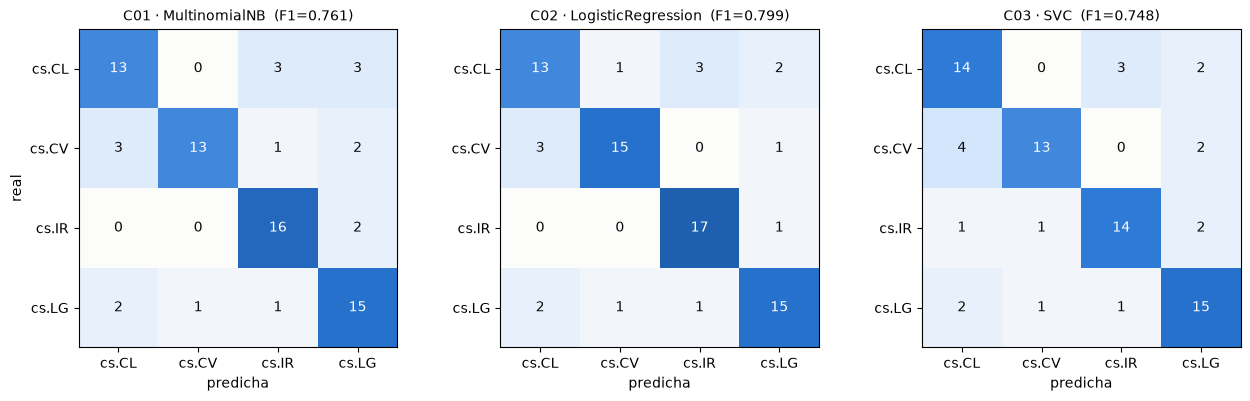

In [8]:
cmap = LinearSegmentedColormap.from_list("blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95"])
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, r in zip(axes, results):
    cm = confusion_table(r["y_dev"], r["y_pred"])
    ax.imshow(cm.values, cmap=cmap, vmin=0, vmax=19)
    for i in range(4):
        for j in range(4):
            v = cm.values[i, j]
            ax.text(j, i, v, ha="center", va="center", fontsize=10,
                    color="white" if v > 11 else "#0b0b0b")
    ax.set_xticks(range(4), config.CLASSES)
    ax.set_yticks(range(4), config.CLASSES)
    ax.set_xlabel("predicha")
    ax.set_title(f"{r['experiment_id']} · {r['model']}  (F1={r['dev_macro_f1']:.3f})", fontsize=10)
axes[0].set_ylabel("real")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "C-1_confusion_dev.png", dpi=150)
plt.show()

In [9]:
# Pares de clases más confundidos (sumando los tres modelos)
pairs = {}
for r in results:
    cm = confusion_table(r["y_dev"], r["y_pred"])
    for g in config.CLASSES:
        for p in config.CLASSES:
            if g != p and cm.loc[g, p]:
                pairs[(g, p)] = pairs.get((g, p), 0) + cm.loc[g, p]
pd.Series(pairs, name="errores").sort_values(ascending=False).rename_axis(["real", "predicha"]).to_frame().head(6)

errores
real  predicha         
cs.CV cs.CL          10
cs.CL cs.IR           9
      cs.LG           7
cs.LG cs.CL           6
cs.IR cs.LG           5
cs.CV cs.LG           5

## 6. Conclusiones del bloque C-1

| Modelo | CV en train | dev | Hiperparámetros |
|---|---|---|---|
| **LogisticRegression** | **0.768 ± 0.022** | **0.799** | C=1, min_df=1 |
| MultinomialNB | 0.759 ± 0.021 | 0.761 | alpha=0.5, min_df=2 |
| SVC lineal | 0.748 ± 0.033 | 0.748 | C=1, min_df=1 |

1. **LogisticRegression es el mejor** en CV y en dev. En dev le saca ~4 puntos a NB y ~5 a SVC, que son unos 3 documentos de 75.
2. **Las diferencias son pequeñas.** En CV los tres están a menos de 2 puntos, dentro de una desviación estándar. Con esta configuración base no hay un ganador claro, y por eso los tres pasan a C-2.
3. **NB es competitivo** con un vocabulario de la mitad de tamaño (3 033 vs 6 689 términos), gracias a `min_df=2`.
4. **cs.CL es la clase más difícil** para los tres (F1 ≈ 0.70) y **cs.IR la más fácil** (F1 0.78-0.87).
5. **Errores más frecuentes:** cs.CV → cs.CL (10 entre los tres modelos), probablemente artículos de modelos visión-lenguaje; cs.CL → cs.IR (9), probablemente artículos de RAG y búsqueda con LLM; y cs.CL ↔ cs.LG (13). Coincide con el cross-listing visto en la Fase 1. Se revisará en el análisis de errores (Fase 3).

**Para C-2:** los tres modelos se prueban con N0, N1 y N2, cada uno con su rejilla de hiperparámetros.

## 7. Registro en `experiments.tsv`

In [10]:
load_experiments()

,experiment_id,task,block,normalization,representation,ngram_range,svd_components,method,hyperparameters,cv_macro_f1,dev_metric,extra,selected,notes
0,C01,classification,C-1,N2,tfidf,"(1,1)",,MultinomialNB,alpha=0.5; min_df=2,0.7594,macro_f1=0.7607; accuracy=0.7600,cv_std=0.0213; n_features=3033; fit_seconds=4.9,no,
1,C02,classification,C-1,N2,tfidf,"(1,1)",,LogisticRegression,C=1; min_df=1,0.7675,macro_f1=0.7993; accuracy=0.8000,cv_std=0.0219; n_features=6689; fit_seconds=1.6,no,
2,C03,classification,C-1,N2,tfidf,"(1,1)",,SVC,C=1; min_df=1,0.7478,macro_f1=0.7481; accuracy=0.7467,cv_std=0.0334; n_features=6689; fit_seconds=1.3,no,
